# Tarea 3 — Elementos Finitos en Diseño Mecánico

## Bloque 1: funciones generales

Coordenadas [radio, z], desplazamientos [ur, uz] y tensiones [rr, zz, tt, rz].


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from scipy.sparse import coo_matrix, csr_matrix
from scipy.sparse.linalg import spsolve


In [2]:
def funciones_forma(r,s):
    N1 = 1 - s - r
    N2 = r
    N3 = s

    dN = np.array([[-1, -1], [1, 0], [0, 1]])

    return N1, N2, N3, dN


def matriz_constitutiva(E, nu):
    D = np.array([[E*(1-nu)/((1+nu)*(1-2*nu)), E*nu/((1+nu)*(1-2*nu)), E*nu/((1+nu)*(1-2*nu)), 0],
                  [E*nu/((1+nu)*(1-2*nu)), E*(1-nu)/((1+nu)*(1-2*nu)), E*nu/((1+nu)*(1-2*nu)), 0],
                  [E*nu/((1+nu)*(1-2*nu)), E*nu/((1+nu)*(1-2*nu)), E*(1-nu)/((1+nu)*(1-2*nu)), 0],
                  [0, 0, 0, E/(2*(1+nu))]])

    return D


def matriz_jacobiana(coord, dN):
    coord = np.array(coord)
    J = coord.T @ dN
    detJ = np.linalg.det(J)
    invJ = np.linalg.inv(J)

    return J, detJ, invJ


def matriz_B(N, dN, invJ, radio):
    B = np.zeros((4, 6))
    for i in range(3):
        B[0, 2*i] = dN[i, 0] * invJ[0, 0] + dN[i, 1] * invJ[1, 0]
        B[1, 2*i+1] = dN[i, 0] * invJ[0, 1] + dN[i, 1] * invJ[1, 1]
        B[2, 2*i] = N[i]/radio
        B[3, 2*i] = dN[i, 0] * invJ[0, 1] + dN[i, 1] * invJ[1, 1]
        B[3, 2*i+1] = dN[i, 0] * invJ[0, 0] + dN[i, 1] * invJ[1, 0]
    return B


def rigidez_elemental(coord, D):
    coord = np.array(coord)
    puntos = [[1/6, 1/6], [2/3, 1/6], [1/6, 2/3]]
    pesos = [1/6, 1/6, 1/6]
    Ke = np.zeros((6, 6))

    for k in range(3):
        r, s = puntos[k]
        N1, N2, N3, dN = funciones_forma(r, s)
        N = np.array([N1, N2, N3])
        radio = N1*coord[0, 0] + N2*coord[1, 0] + N3*coord[2, 0]
        J, detJ, invJ = matriz_jacobiana(coord, dN)
        B = matriz_B(N, dN, invJ, radio)
        Ke += 2*np.pi * pesos[k] * B.T @ D @ B * radio * abs(detJ)

    return Ke


def gdl_elemento(nodos):
    gdl = []
    for i in nodos:
        gdl.append(2*i)
        gdl.append(2*i+1)

    return gdl


def ensamblar_rigidez_global(coordenadas, conectividad, E, nu):
    coordenadas = np.array(coordenadas)
    n_gdl = 2*len(coordenadas)
    filas, columnas, valores = [], [], []
    D = matriz_constitutiva(E, nu)

    for nodos in conectividad:
        Ke = rigidez_elemental(coordenadas[nodos], D)
        gdl = gdl_elemento(nodos)
        for i in range(6):
            for j in range(6):
                filas.append(gdl[i])
                columnas.append(gdl[j])
                valores.append(Ke[i, j])

    K = coo_matrix((valores, (filas, columnas)), shape=(n_gdl, n_gdl)).tocsr()
    return K


def resolver_sistema(K, F, gdl_restringidos):
    K = csr_matrix(K)
    F = np.array(F)
    n_gdl = len(F)
    gdl_libres = np.setdiff1d(np.arange(n_gdl), gdl_restringidos)

    K_libre = K[gdl_libres][:, gdl_libres]
    U = np.zeros(n_gdl)
    U[gdl_libres] = spsolve(K_libre, F[gdl_libres])
    R = K @ U - F

    return U, R


def calcular_tensiones(coords_elem, U_elem, D, puntos):
    coords_elem = np.array(coords_elem)
    sigma = np.zeros((len(puntos), 4))

    for k in range(len(puntos)):
        r, s = puntos[k]
        N1, N2, N3, dN = funciones_forma(r, s)
        N = np.array([N1, N2, N3])
        radio = N1*coords_elem[0, 0] + N2*coords_elem[1, 0] + N3*coords_elem[2, 0]
        J, detJ, invJ = matriz_jacobiana(coords_elem, dN)
        B = matriz_B(N, dN, invJ, radio)
        epsilon = B @ U_elem
        sigma[k] = D @ epsilon

    return sigma


def von_mises(sigma):
    sigma_rr = sigma[0]
    sigma_zz = sigma[1]
    sigma_tt = sigma[2]
    tau_rz = sigma[3]

    sigma_vm = np.sqrt(((sigma_rr-sigma_zz)**2 + (sigma_zz-sigma_tt)**2 + (sigma_tt-sigma_rr)**2)/2 + 3*tau_rz**2)

    return sigma_vm


def calidad_triangulos(coordenadas, conectividad):
    triangulos = coordenadas[conectividad]
    lados = np.zeros((len(conectividad), 3))
    for i in range(3):
        lados[:, i] = np.linalg.norm(triangulos[:, (i+1)%3]-triangulos[:, i], axis=1)

    v1 = triangulos[:, 1]-triangulos[:, 0]
    v2 = triangulos[:, 2]-triangulos[:, 0]
    areas = np.abs(v1[:, 0]*v2[:, 1]-v1[:, 1]*v2[:, 0])/2
    relaciones = np.max(lados, axis=1)**2/(2*areas)
    angulos = np.zeros((len(conectividad), 3))
    for i in range(3):
        a = lados[:, i]
        b = lados[:, (i+1)%3]
        c = lados[:, (i+2)%3]
        coseno = (b**2+c**2-a**2)/(2*b*c)
        angulos[:, i] = np.degrees(np.arccos(np.clip(coseno, -1, 1)))
    return relaciones, np.min(angulos, axis=1)


def fuerzas_borde_axisimetrico(coord, traccion):
    """Traccion constante [tr, tz]; devuelve [fr1, fz1, fr2, fz2]."""
    coord = np.array(coord)
    longitud = np.linalg.norm(coord[1]-coord[0])
    puntos = [-1/np.sqrt(3), 1/np.sqrt(3)]
    f = np.zeros(4)

    for xi in puntos:
        N = np.array([(1-xi)/2, (1+xi)/2])
        radio = N @ coord[:, 0]
        f[0::2] += 2*np.pi * N * traccion[0] * radio * longitud/2
        f[1::2] += 2*np.pi * N * traccion[1] * radio * longitud/2

    return f


## Bloque 2: geometría y malla del eje

Se usa d = 1, D = 1.25*d y r_transicion = 0.125*d. El hombro está en z = 0 y el arco termina en z = r_transicion. L_grueso y L_delgado se miden desde z = 0; se parte con 2.5*d para alejar los extremos del hombro. Son parámetros de trabajo, no datos del enunciado.

Como r_transicion = (D-d)/2, desaparece la cara radial plana y queda una arista convexa de 90° junto al tramo grueso. Se conserva el filete circular, tangente a la cara radial y al tramo delgado.

La malla se genera con puntos refinados cerca del hombro y triangulación de Matplotlib. El arco se aproxima mediante cuerdas ligeramente exteriores al círculo exacto; se informa su desviación y se comprueba el contorno poligonal. Se informa la calidad mediante lado mayor / altura menor y el ángulo mínimo.

La validación del cilindro uniforme está en `validacion_cilindro.py`.


In [3]:
def dividir_tramo(longitud, h_cerca, h_lejos):
    distancias = [0.0]
    while distancias[-1] < longitud:
        paso = min(h_lejos, h_cerca + 0.25*distancias[-1])
        siguiente = min(distancias[-1] + paso, longitud)
        if longitud - siguiente < 0.3*paso:
            siguiente = longitud
        distancias.append(siguiente)
    return np.array(distancias)


def generar_malla_eje(d, D, r_transicion, L_grueso, L_delgado,
                     h_cerca, h_lejos, n_radial, n_arco):
    z_grueso = -dividir_tramo(L_grueso, h_cerca, h_lejos)[::-1]
    angulos = np.linspace(0, np.pi/2, n_arco+1)
    z_arco = r_transicion*(1-np.cos(angulos))
    radio_arco = d/2 + r_transicion*(1-np.sin(angulos))
    z_delgado = r_transicion + dividir_tramo(L_delgado-r_transicion, h_cerca, h_lejos)

    z_perfil = np.concatenate((z_grueso, z_arco[1:], z_delgado[1:]))
    radios = np.concatenate((np.full(len(z_grueso), D/2),
                             radio_arco[1:], np.full(len(z_delgado)-1, d/2)))

    t = np.linspace(0, 1, n_radial+1)
    fracciones = 1-(1-t)**1.5
    coordenadas = np.column_stack((radios, z_perfil)).tolist()
    nodos_exterior = np.arange(len(coordenadas))

    bordes = {"nodos_exterior": nodos_exterior}
    for nombre, radio, z, nodo_final in [
            ("extremo_grueso", D/2, -L_grueso, nodos_exterior[0]),
            ("extremo_delgado", d/2, L_delgado, nodos_exterior[-1])]:
        nodos = []
        for fraccion in t[:-1]:
            nodos.append(len(coordenadas))
            coordenadas.append([radio*fraccion, z])
        nodos.append(nodo_final)
        bordes["nodos_"+nombre] = np.array(nodos)

    paso_eje = min(h_lejos, d/n_radial)
    z_eje = np.concatenate((-dividir_tramo(L_grueso, paso_eje, h_lejos)[::-1],
                            dividir_tramo(L_delgado, paso_eje, h_lejos)[1:]))
    nodos_eje = [bordes["nodos_extremo_grueso"][0]]
    for z in z_eje[1:-1]:
        nodos_eje.append(len(coordenadas))
        coordenadas.append([0, z])
    nodos_eje.append(bordes["nodos_extremo_delgado"][0])
    contorno = np.array(coordenadas)

    # Refinamiento cerca del filete; paso mayor hacia el eje.
    for i in range(1, n_radial):
        radio_fila = D/2*fracciones[i]
        paso = min(h_lejos, h_cerca + 0.3*max(d/2-radio_fila, 0))
        z_fila = np.concatenate((-dividir_tramo(L_grueso, paso, h_lejos)[::-1],
                                 dividir_tramo(L_delgado, paso, h_lejos)[1:]))
        for z in z_fila[1:-1]:
            distancia = max(-z, z-r_transicion, 0)
            peso = max(0, 1-distancia/d)
            posicion = (1-peso)*t[i] + peso*fracciones[i]
            radio = np.interp(z, z_perfil, radios)*posicion
            separacion = max(0.5*h_cerca, 0.2*min(h_lejos, h_cerca+0.25*distancia))
            if np.min(np.linalg.norm(contorno-[radio, z], axis=1)) >= separacion:
                coordenadas.append([radio, z])
    coordenadas = np.array(coordenadas)

    conectividad = mtri.Triangulation(coordenadas[:, 0], coordenadas[:, 1]).triangles
    centros = np.mean(coordenadas[conectividad], axis=1)
    dentro = centros[:, 0] <= np.interp(centros[:, 1], z_perfil, radios)
    conectividad = conectividad[dentro]

    bordes["nodos_eje"] = np.array(nodos_eje)
    bordes["nodos_arco"] = nodos_exterior[(z_perfil >= 0) & (z_perfil <= r_transicion)]
    for nombre in ["eje", "extremo_grueso", "extremo_delgado", "exterior", "arco"]:
        nodos = bordes["nodos_"+nombre]
        bordes[nombre] = np.column_stack((nodos[:-1], nodos[1:]))

    return coordenadas, conectividad, bordes


In [4]:
def comprobar_malla(coordenadas, conectividad, bordes):
    if (conectividad.ndim != 2 or conectividad.shape[1] != 3
            or not np.issubdtype(conectividad.dtype, np.integer)):
        raise ValueError("La conectividad debe contener tres indices enteros por elemento.")
    if np.any(conectividad < 0) or np.any(conectividad >= len(coordenadas)):
        raise ValueError("Hay indices fuera de la malla.")
    if not np.all(np.isfinite(coordenadas)) or len(np.unique(conectividad)) != len(coordenadas):
        raise ValueError("Hay coordenadas no finitas o nodos sin elementos.")

    triangulos = coordenadas[conectividad]
    v1 = triangulos[:, 1]-triangulos[:, 0]
    v2 = triangulos[:, 2]-triangulos[:, 0]
    areas = (v1[:, 0]*v2[:, 1]-v1[:, 1]*v2[:, 0])/2
    escala = np.max(np.ptp(coordenadas, axis=0))
    if np.any(areas <= 1e-12*escala**2):
        raise ValueError("Hay elementos degenerados o con orientacion negativa.")

    exterior = coordenadas[bordes["nodos_exterior"]]
    radios, z = exterior[:, 0], exterior[:, 1]
    tolerancia = 1e-10*escala
    if np.any(np.diff(z) <= 0):
        raise ValueError("El perfil debe avanzar en z.")
    if (np.any(coordenadas[:, 0] < -tolerancia)
            or np.any(coordenadas[:, 0] > np.interp(coordenadas[:, 1], z, radios)+tolerancia)
            or np.any(coordenadas[:, 1] < z[0]-tolerancia)
            or np.any(coordenadas[:, 1] > z[-1]+tolerancia)):
        raise ValueError("Hay nodos fuera del contorno discretizado.")

    # En Delaunay, el contorno completo impide huecos y atajos sobre el filete.
    aristas = np.vstack((conectividad[:, [0, 1]], conectividad[:, [1, 2]],
                         conectividad[:, [2, 0]]))
    aristas, repeticiones = np.unique(np.sort(aristas, axis=1), axis=0, return_counts=True)
    contorno = np.vstack((bordes["eje"], bordes["extremo_grueso"],
                          bordes["extremo_delgado"], bordes["exterior"]))
    contorno = np.unique(np.sort(contorno, axis=1), axis=0)
    if np.any(repeticiones > 2) or not np.array_equal(aristas[repeticiones == 1], contorno):
        raise ValueError("La triangulacion no respeta el contorno completo.")

    area_perfil = np.sum((radios[:-1]+radios[1:])*np.diff(z)/2)
    if not np.isclose(np.sum(areas), area_perfil, rtol=1e-10):
        raise ValueError("Las areas de la malla y del perfil no coinciden.")
    return areas


In [5]:
d = 1
D = 1.25*d
r_transicion = 0.125*d
L_grueso = 2.5*d
L_delgado = 2.5*d

h_cerca = 0.02*d
h_lejos = 0.20*d
n_radial = 12
n_arco = 12

coordenadas, conectividad, bordes = generar_malla_eje(
    d, D, r_transicion, L_grueso, L_delgado,
    h_cerca, h_lejos, n_radial, n_arco)

areas = comprobar_malla(coordenadas, conectividad, bordes)
error_arco = r_transicion*(1-np.cos(np.pi/(4*n_arco)))
relaciones, angulos_minimos = calidad_triangulos(coordenadas, conectividad)
cerca_arco = np.any(np.isin(conectividad, bordes["nodos_arco"]), axis=1)

print("Malla valida:", len(coordenadas), "nodos y", len(conectividad), "elementos T3")
print(f"Area minima: {np.min(areas):.6e}   Area total: {np.sum(areas):.6f}")
print(f"Relacion maxima: global = {np.max(relaciones):.2f}; arco = {np.max(relaciones[cerca_arco]):.2f}")
print(f"Angulo minimo: global = {np.min(angulos_minimos):.2f}; arco = {np.min(angulos_minimos[cerca_arco]):.2f} grados")
print(f"Desviacion maxima de las cuerdas: {error_arco/d:.3e} d")


Malla valida: 445 nodos y 786 elementos T3
Area minima: 5.970808e-05   Area total: 2.815888
Relacion maxima: global = 6.60; arco = 4.43
Angulo minimo: global = 10.36; arco = 17.44 grados
Desviacion maxima de las cuerdas: 2.676e-04 d


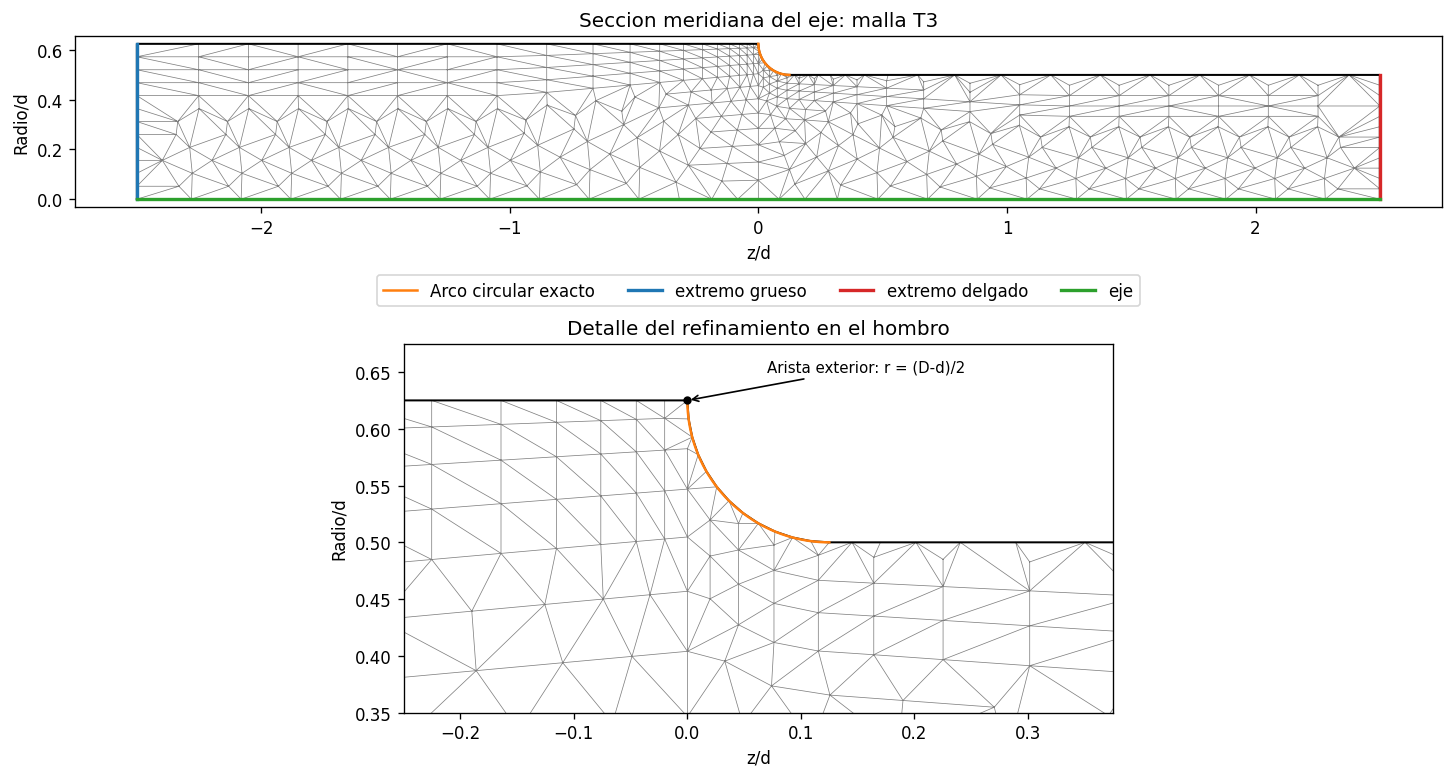

In [6]:
fig, ejes = plt.subplots(2, 1, figsize=(12, 7), constrained_layout=True)

exterior = coordenadas[bordes["nodos_exterior"]]
contorno = np.vstack(([0, -L_grueso], exterior,
                      [0, L_delgado], [0, -L_grueso]))
angulos = np.linspace(0, np.pi/2, 200)
z_arco = r_transicion*(1-np.cos(angulos))
radio_arco = d/2+r_transicion*(1-np.sin(angulos))

for ax in ejes:
    ax.triplot(coordenadas[:, 1]/d, coordenadas[:, 0]/d,
               conectividad, color="0.5", linewidth=0.45)
    ax.plot(contorno[:, 1]/d, contorno[:, 0]/d, color="black", linewidth=1.2)
    ax.plot(z_arco/d, radio_arco/d, color="tab:orange", linewidth=1.5,
            label="Arco circular exacto")
    ax.set_aspect("equal")
    ax.set_xlabel("z/d")
    ax.set_ylabel("Radio/d")

for nombre, color in [("extremo_grueso", "tab:blue"),
                      ("extremo_delgado", "tab:red"), ("eje", "tab:green")]:
    nodos = bordes["nodos_"+nombre]
    ejes[0].plot(coordenadas[nodos, 1]/d, coordenadas[nodos, 0]/d,
                 color=color, linewidth=2, label=nombre.replace("_", " "))

ejes[0].set_title("Seccion meridiana del eje: malla T3")
ejes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.35), ncol=4)
ejes[1].set_xlim(-0.25, r_transicion/d+0.25)
ejes[1].set_ylim(d/2/d-0.15, D/2/d+0.05)
ejes[1].plot(0, D/(2*d), "ko", markersize=4)
ejes[1].annotate("Arista exterior: r = (D-d)/2", xy=(0, D/(2*d)),
                 xytext=(0.07, D/(2*d)+0.025), fontsize=9,
                 arrowprops={"arrowstyle": "->"})
ejes[1].set_title("Detalle del refinamiento en el hombro")
plt.show()


## Bloque 3: cargas, condiciones de borde y resolución

Se interpreta d = 1 mm. Se adoptan E = 210000 MPa, nu = 0.3 y sigma_0 = 100 MPa; no son datos explícitos del enunciado. La fuerza total es P = sigma_0*pi*d**2/4.

Se impone ur = 0 en el eje y uz = 0 en el extremo grueso. En el extremo delgado se aplica una tracción uniforme hacia +z, integrada sobre cada segmento con dos puntos de Gauss y el factor 2*pi*radio. El contorno exterior queda libre.


In [7]:
E = 210000  # MPa
nu = 0.3
sigma_0 = 100  # MPa
P = sigma_0*np.pi*d**2/4  # N

n_gdl = 2*len(coordenadas)
F = np.zeros(n_gdl)
traccion = np.array([0, sigma_0])

for nodos in bordes["extremo_delgado"]:
    f = fuerzas_borde_axisimetrico(coordenadas[nodos], traccion)
    gdl = gdl_elemento(nodos)
    F[gdl] += f

fuerza_axial = np.sum(F[1::2])
assert np.isclose(fuerza_axial, P, rtol=1e-10, atol=1e-12)

gdl_restringidos = []
for nodo in bordes["nodos_eje"]:
    gdl_restringidos.append(2*nodo)
for nodo in bordes["nodos_extremo_grueso"]:
    gdl_restringidos.append(2*nodo+1)


In [8]:
K = ensamblar_rigidez_global(coordenadas, conectividad, E, nu)
U, R = resolver_sistema(K, F, gdl_restringidos)


In [9]:
reaccion_axial = np.sum(R[2*bordes["nodos_extremo_grueso"]+1])
error_equilibrio = abs(fuerza_axial+reaccion_axial)/P
uz_max = np.max(U[1::2])
assert error_equilibrio < 1e-8

print("Numero de grados de libertad:", n_gdl)
print(f"Fuerza axial aplicada: {fuerza_axial:.6f} N")
print(f"Suma de reacciones axiales: {reaccion_axial:.6f} N")
print(f"Error relativo de equilibrio: {error_equilibrio:.3e}")
print(f"Desplazamiento axial maximo: {uz_max:.6e} mm")


Numero de grados de libertad: 890
Fuerza axial aplicada: 78.539816 N
Suma de reacciones axiales: -78.539816 N
Error relativo de equilibrio: 8.034e-14
Desplazamiento axial maximo: 1.964287e-03 mm


## Bloque 4: tensiones y factores de concentración

Se calculan las tensiones en los tres puntos de Gauss de cada T3. Para los gráficos se usa el promedio de Von Mises por elemento; los máximos se buscan entre todos los puntos de Gauss.

Kt_VM usa la tensión equivalente y Kt_zz la componente axial, ambas divididas por sigma_nom. Son resultados preliminares de la malla actual, todavía sin verificar por convergencia.


In [10]:
D_material = matriz_constitutiva(E, nu)
puntos_gauss = [[1/6, 1/6], [2/3, 1/6], [1/6, 2/3]]
n_elementos = len(conectividad)
tensiones = np.zeros((n_elementos, 3, 4))
sigma_vm = np.zeros((n_elementos, 3))
coordenadas_gauss = np.zeros((n_elementos, 3, 2))

for e in range(n_elementos):
    nodos = conectividad[e]
    coords_elem = coordenadas[nodos]
    U_elem = U[gdl_elemento(nodos)]
    tensiones[e] = calcular_tensiones(coords_elem, U_elem, D_material, puntos_gauss)

    for k in range(3):
        sigma_vm[e, k] = von_mises(tensiones[e, k])
        r, s = puntos_gauss[k]
        N1, N2, N3, dN = funciones_forma(r, s)
        coordenadas_gauss[e, k] = np.array([N1, N2, N3]) @ coords_elem

sigma_vm_media = np.mean(sigma_vm, axis=1)


In [11]:
sigma_nom = P/(np.pi*d**2/4)
e_vm, k_vm = np.unravel_index(np.argmax(sigma_vm), sigma_vm.shape)
e_zz, k_zz = np.unravel_index(np.argmax(tensiones[:, :, 1]), (n_elementos, 3))

sigma_vm_max = sigma_vm[e_vm, k_vm]
sigma_zz_max = tensiones[e_zz, k_zz, 1]
Kt_VM = sigma_vm_max/sigma_nom
Kt_zz = sigma_zz_max/sigma_nom
r_vm, z_vm = coordenadas_gauss[e_vm, k_vm]
r_zz, z_zz = coordenadas_gauss[e_zz, k_zz]

print(f"Tension nominal: {sigma_nom:.6f} MPa")
print(f"Maximo Von Mises: {sigma_vm_max:.6f} MPa")
print(f"Maximo esfuerzo axial: {sigma_zz_max:.6f} MPa")
print(f"Kt_VM = {Kt_VM:.6f}")
print(f"Kt_zz = {Kt_zz:.6f}")
print(f"Posicion del maximo VM: (radio, z) = ({r_vm:.6f}, {z_vm:.6f}) mm")
print(f"Posicion del maximo axial: (radio, z) = ({r_zz:.6f}, {z_zz:.6f}) mm")


Tension nominal: 100.000000 MPa
Maximo Von Mises: 155.982277 MPa
Maximo esfuerzo axial: 163.942925 MPa
Kt_VM = 1.559823
Kt_zz = 1.639429
Posicion del maximo VM: (radio, z) = (0.504042, 0.087334) mm
Posicion del maximo axial: (radio, z) = (0.501116, 0.099098) mm


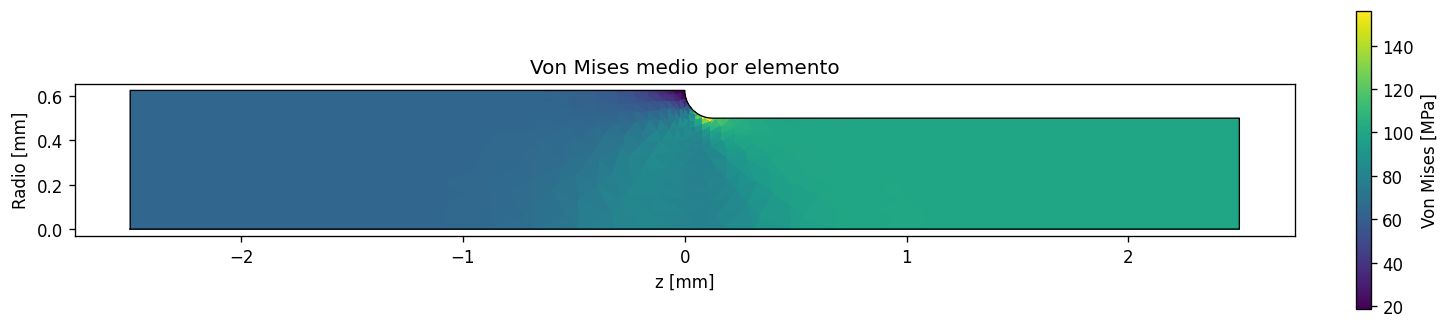

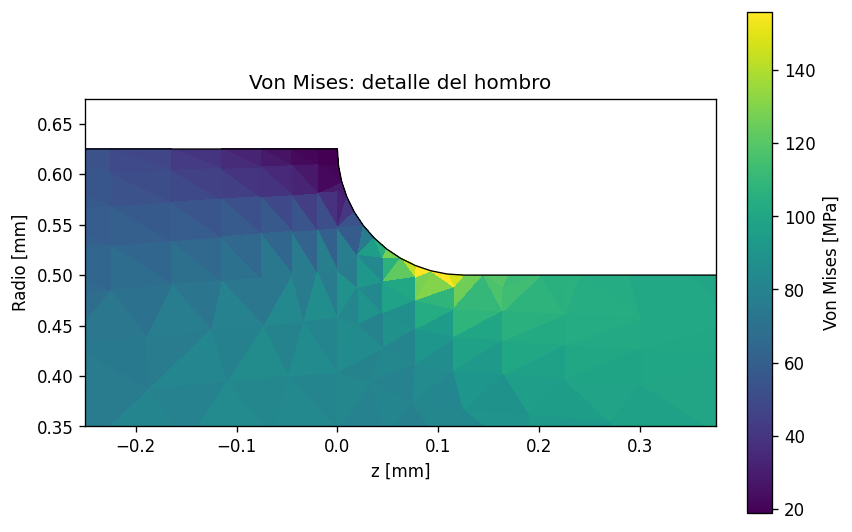

In [12]:
import os

os.makedirs("Graficos", exist_ok=True)
triangulacion = mtri.Triangulation(coordenadas[:, 1], coordenadas[:, 0], conectividad)

for detalle, nombre, tamano in [
        (False, "von_mises_eje", (12, 3)),
        (True, "von_mises_hombro", (7, 5))]:
    fig, ax = plt.subplots(figsize=tamano, constrained_layout=True)
    mapa = ax.tripcolor(triangulacion, facecolors=sigma_vm_media, shading="flat",
                       cmap="viridis", vmin=np.min(sigma_vm_media), vmax=np.max(sigma_vm_media))
    ax.plot(contorno[:, 1], contorno[:, 0], color="black", linewidth=0.8)
    ax.set_aspect("equal")
    ax.set_xlabel("z [mm]")
    ax.set_ylabel("Radio [mm]")
    ax.set_title("Von Mises medio por elemento")
    fig.colorbar(mapa, ax=ax, label="Von Mises [MPa]", shrink=0.85)

    if detalle:
        ax.set_xlim(-0.25*d, r_transicion+0.25*d)
        ax.set_ylim(d/2-0.15*d, D/2+0.05*d)
        ax.set_title("Von Mises: detalle del hombro")

    fig.savefig("Graficos/"+nombre+".png", dpi=300, bbox_inches="tight")
    plt.show()


## Bloque 5: convergencia de la malla

Se usan factores de refinamiento 1, 1.5, 2 y 3: se dividen h_cerca y h_lejos por el factor y se multiplican n_radial y n_arco. La geometría física, longitudes, material y carga se mantienen. Al refinar el arco también mejora su aproximación por cuerdas.

El ensamblaje suma las contribuciones en una matriz dispersa de SciPy y la resolución usa `spsolve`, con la misma formulación y restricciones. La función siguiente repite el problema del eje para cada malla.

Se calcula el cambio porcentual absoluto respecto del valor de la malla anterior. Un cambio menor al 1 % es una referencia práctica: se estudian máximos en puntos de Gauss, que no equivalen a la tensión máxima superficial.

Se registran las coordenadas físicas [radio, z] de los puntos de Gauss donde aparece cada máximo.

Sobre el filete se evalúa el punto medio de cada segmento recto del arco desde su único T3 adyacente. Se usan sus coordenadas naturales con `calcular_tensiones()`, sin promediar ni suavizar tensiones entre elementos. Es un muestreo del contorno discretizado; no se proyectan los puntos al círculo exacto ni se impone una condición adicional a las tensiones calculadas.


In [13]:
def resolver_eje(coordenadas, conectividad, bordes, E, nu, sigma_0, d):
    n_gdl = 2*len(coordenadas)
    F = np.zeros(n_gdl)
    P = sigma_0*np.pi*d**2/4
    for nodos in bordes["extremo_delgado"]:
        f = fuerzas_borde_axisimetrico(coordenadas[nodos], [0, sigma_0])
        F[gdl_elemento(nodos)] += f
    assert np.isclose(np.sum(F[1::2]), P, rtol=1e-10, atol=1e-12)

    gdl_restringidos = []
    for nodo in bordes["nodos_eje"]:
        gdl_restringidos.append(2*nodo)
    for nodo in bordes["nodos_extremo_grueso"]:
        gdl_restringidos.append(2*nodo+1)

    K = ensamblar_rigidez_global(coordenadas, conectividad, E, nu)
    U, R = resolver_sistema(K, F, gdl_restringidos)
    reaccion = np.sum(R[2*bordes["nodos_extremo_grueso"]+1])
    error_equilibrio = abs(np.sum(F[1::2])+reaccion)/P
    assert error_equilibrio < 1e-8

    D_material = matriz_constitutiva(E, nu)
    puntos = [[1/6, 1/6], [2/3, 1/6], [1/6, 2/3]]
    sigma_vm_max = 0
    sigma_zz_max = -np.inf
    posicion_vm = np.zeros(2)
    posicion_zz = np.zeros(2)
    for e, nodos in enumerate(conectividad):
        U_elem = U[gdl_elemento(nodos)]
        tensiones = calcular_tensiones(coordenadas[nodos], U_elem, D_material, puntos)
        for k, sigma in enumerate(tensiones):
            r, s = puntos[k]
            N1, N2, N3, dN = funciones_forma(r, s)
            posicion = np.array([N1, N2, N3]) @ coordenadas[nodos]
            sigma_vm = von_mises(sigma)
            if sigma_vm > sigma_vm_max:
                sigma_vm_max = sigma_vm
                posicion_vm = posicion
                elemento_vm = e
            if sigma[1] > sigma_zz_max:
                sigma_zz_max = sigma[1]
                posicion_zz = posicion
                elemento_zz = e

    sigma_vm_filete = 0
    sigma_zz_filete = -np.inf
    for borde in bordes["arco"]:
        adyacentes = np.flatnonzero(np.sum(np.isin(conectividad, borde), axis=1) == 2)
        assert len(adyacentes) == 1
        nodos = conectividad[adyacentes[0]]
        N = np.zeros(3)
        N[np.isin(nodos, borde)] = 0.5
        punto_medio = [[N[1], N[2]]]
        U_elem = U[gdl_elemento(nodos)]
        sigma = calcular_tensiones(coordenadas[nodos], U_elem, D_material, punto_medio)[0]
        vm_filete = von_mises(sigma)
        if vm_filete > sigma_vm_filete:
            sigma_vm_filete = vm_filete
            elemento_vm_filete = adyacentes[0]
        if sigma[1] > sigma_zz_filete:
            sigma_zz_filete = sigma[1]
            elemento_zz_filete = adyacentes[0]

    sigma_nom = P/(np.pi*d**2/4)
    return {"nodos": len(coordenadas), "elementos": len(conectividad), "gdl": n_gdl,
            "Kt_VM": sigma_vm_max/sigma_nom, "Kt_zz": sigma_zz_max/sigma_nom,
            "error_equilibrio": error_equilibrio,
            "posicion_VM": posicion_vm, "posicion_zz": posicion_zz,
            "sigma_VM_Gauss": sigma_vm_max, "sigma_zz_Gauss": sigma_zz_max,
            "sigma_VM_filete": sigma_vm_filete, "sigma_zz_filete": sigma_zz_filete,
            "Kt_VM_filete": sigma_vm_filete/sigma_nom,
            "Kt_zz_filete": sigma_zz_filete/sigma_nom,
            "elemento_VM": elemento_vm, "elemento_zz": elemento_zz,
            "elemento_VM_filete": elemento_vm_filete,
            "elemento_zz_filete": elemento_zz_filete}


In [14]:
niveles = [("Actual", 1), ("Intermedia", 1.5), ("Fina", 2), ("Factor 3", 3)]
resultados_convergencia = []

for nombre, factor in niveles:
    coords_malla, conn_malla, bordes_malla = generar_malla_eje(
        d, D, r_transicion, L_grueso, L_delgado,
        h_cerca/factor, h_lejos/factor, int(n_radial*factor), int(n_arco*factor))
    comprobar_malla(coords_malla, conn_malla, bordes_malla)
    resultado = resolver_eje(coords_malla, conn_malla, bordes_malla, E, nu, sigma_0, d)
    resultado["malla"] = nombre
    resultado["factor"] = factor
    resultado["cambio_VM"] = np.nan
    resultado["cambio_zz"] = np.nan
    resultado["cambio_VM_filete"] = np.nan
    resultado["cambio_zz_filete"] = np.nan
    if len(resultados_convergencia) > 0:
        anterior = resultados_convergencia[-1]
        resultado["cambio_VM"] = 100*abs(resultado["Kt_VM"]-anterior["Kt_VM"])/abs(anterior["Kt_VM"])
        resultado["cambio_zz"] = 100*abs(resultado["Kt_zz"]-anterior["Kt_zz"])/abs(anterior["Kt_zz"])
        for tipo in ["VM", "zz"]:
            clave = "Kt_"+tipo+"_filete"
            resultado["cambio_"+tipo+"_filete"] = 100*abs(resultado[clave]-anterior[clave])/abs(anterior[clave])
    resultados_convergencia.append(resultado)

print("Maximos de tension [MPa]")
print(f"{'Malla':<12} {'VM Gauss':>12} {'VM filete':>12} {'zz Gauss':>12} {'zz filete':>12}")
for resultado in resultados_convergencia:
    print(f'{resultado["malla"]:<12} {resultado["sigma_VM_Gauss"]:12.6f} '
          f'{resultado["sigma_VM_filete"]:12.6f} {resultado["sigma_zz_Gauss"]:12.6f} '
          f'{resultado["sigma_zz_filete"]:12.6f}')

print("\nFactores de concentracion: Gauss y puntos medios del filete")
print(f"{'Malla':<12} {'Nodos':>6} {'T3':>6} {'GDL':>6} {'Kt_VM G':>11} {'Kt_VM F':>11} {'Kt_zz G':>11} {'Kt_zz F':>11}")
for resultado in resultados_convergencia:
    print(f'{resultado["malla"]:<12} {resultado["nodos"]:6d} {resultado["elementos"]:6d} {resultado["gdl"]:6d} '
          f'{resultado["Kt_VM"]:11.6f} {resultado["Kt_VM_filete"]:11.6f} '
          f'{resultado["Kt_zz"]:11.6f} {resultado["Kt_zz_filete"]:11.6f}')

print("\nCambios absolutos respecto de la malla anterior [%]")
print(f"{'Malla':<12} {'VM Gauss':>12} {'VM filete':>12} {'zz Gauss':>12} {'zz filete':>12}")
for resultado in resultados_convergencia[1:]:
    print(f'{resultado["malla"]:<12} {resultado["cambio_VM"]:12.3f} '
          f'{resultado["cambio_VM_filete"]:12.3f} {resultado["cambio_zz"]:12.3f} '
          f'{resultado["cambio_zz_filete"]:12.3f}')

print("\nPosiciones de los maximos en puntos de Gauss [mm]")
print(f"{'Malla':<12} {'Radio VM':>12} {'z VM':>12} {'Radio zz':>12} {'z zz':>12}")
for resultado in resultados_convergencia:
    r_vm_malla, z_vm_malla = resultado["posicion_VM"]
    r_zz_malla, z_zz_malla = resultado["posicion_zz"]
    print(f'{resultado["malla"]:<12} {r_vm_malla:12.6f} {z_vm_malla:12.6f} '
          f'{r_zz_malla:12.6f} {z_zz_malla:12.6f}')


Maximos de tension [MPa]
Malla            VM Gauss    VM filete     zz Gauss    zz filete
Actual         155.982277   155.968064   163.942925   163.828113
Intermedia     161.894296   161.898218   169.395967   169.295840
Fina           162.881196   162.852036   173.477847   173.371535
Factor 3       166.434294   166.406544   172.687359   172.000973

Factores de concentracion: Gauss y puntos medios del filete
Malla         Nodos     T3    GDL     Kt_VM G     Kt_VM F     Kt_zz G     Kt_zz F
Actual          445    786    890    1.559823    1.559681    1.639429    1.638281
Intermedia      875   1601   1750    1.618943    1.618982    1.693960    1.692958
Fina           1449   2707   2898    1.628812    1.628520    1.734778    1.733715
Factor 3       3031   5787   6062    1.664343    1.664065    1.726874    1.720010

Cambios absolutos respecto de la malla anterior [%]
Malla            VM Gauss    VM filete     zz Gauss    zz filete
Intermedia          3.790        3.802        3.326        3.

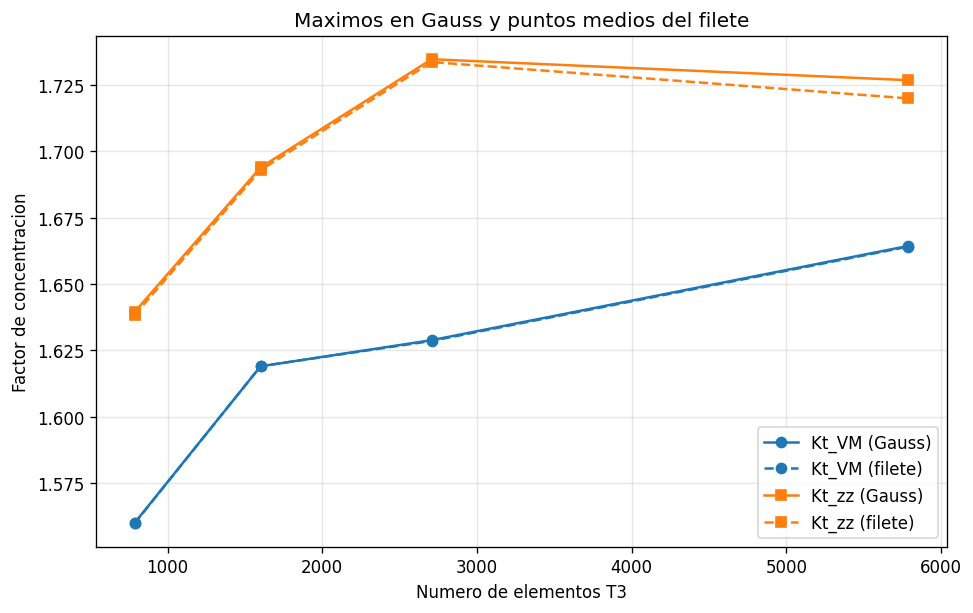

In [15]:
elementos_mallas = [resultado["elementos"] for resultado in resultados_convergencia]
kt_vm_mallas = [resultado["Kt_VM"] for resultado in resultados_convergencia]
kt_zz_mallas = [resultado["Kt_zz"] for resultado in resultados_convergencia]

fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
ax.plot(elementos_mallas, kt_vm_mallas, "o-", color="tab:blue", label="Kt_VM (Gauss)")
ax.plot(elementos_mallas, [r["Kt_VM_filete"] for r in resultados_convergencia],
        "o--", color="tab:blue", label="Kt_VM (filete)")
ax.plot(elementos_mallas, kt_zz_mallas, "s-", color="tab:orange", label="Kt_zz (Gauss)")
ax.plot(elementos_mallas, [r["Kt_zz_filete"] for r in resultados_convergencia],
        "s--", color="tab:orange", label="Kt_zz (filete)")
ax.set_xlabel("Numero de elementos T3")
ax.set_ylabel("Factor de concentracion")
ax.set_title("Maximos en Gauss y puntos medios del filete")
ax.grid(True, alpha=0.3)
ax.legend()
fig.savefig("Graficos/convergencia_Kt.png", dpi=300, bbox_inches="tight")
plt.show()


In [16]:
ultima = resultados_convergencia[-1]
cambios = [ultima["cambio_VM"], ultima["cambio_zz"],
           ultima["cambio_VM_filete"], ultima["cambio_zz_filete"]]
if max(cambios) < 1:
    print("Los cuatro cambios del ultimo paso son menores al 1 %: hay indicios preliminares de estabilizacion.")
else:
    print("No se alcanza un cambio menor al 1 % en los cuatro indicadores.")
    print("Las mallas evaluadas todavia no permiten afirmar estabilizacion de todos los maximos.")
print("El filete se evalua en puntos medios desde el T3 adyacente, sin promediar entre elementos.")
print("Este muestreo del borde no demuestra la convergencia del maximo superficial continuo.")


No se alcanza un cambio menor al 1 % en los cuatro indicadores.
Las mallas evaluadas todavia no permiten afirmar estabilizacion de todos los maximos.
El filete se evalua en puntos medios desde el T3 adyacente, sin promediar entre elementos.
Este muestreo del borde no demuestra la convergencia del maximo superficial continuo.


### Comprobación con arco fijo

Se mantiene n_arco = 36, igual al nivel más fino anterior, y se varían solamente h_cerca, h_lejos y n_radial con los mismos cuatro factores. Así se conserva exactamente el perfil poligonal del filete; no se presupone que su aproximación geométrica ya haya convergido.

Se revisan validez, lado mayor / altura menor y ángulo mínimo. La comparación con el estudio anterior mantiene los mismos parámetros del resto de la malla; cambiar n_arco también redistribuye los T3 adyacentes, por lo que esa diferencia no mide exclusivamente el error geométrico.


In [17]:
n_arco_fijo = 3*n_arco
resultados_arco_fijo = []
claves_kt = ["Kt_VM", "Kt_VM_filete", "Kt_zz", "Kt_zz_filete"]

for nombre, factor in niveles:
    coords_fijas, conn_fija, bordes_fijos = generar_malla_eje(
        d, D, r_transicion, L_grueso, L_delgado,
        h_cerca/factor, h_lejos/factor, int(n_radial*factor), n_arco_fijo)
    comprobar_malla(coords_fijas, conn_fija, bordes_fijos)
    relaciones_fijas, angulos_fijos = calidad_triangulos(coords_fijas, conn_fija)
    resultado = resolver_eje(coords_fijas, conn_fija, bordes_fijos, E, nu, sigma_0, d)
    resultado["malla"] = nombre
    resultado["factor"] = factor
    resultado["aspecto_max"] = np.max(relaciones_fijas)
    resultado["angulo_min"] = np.min(angulos_fijos)
    for clave in claves_kt:
        resultado["cambio_"+clave] = np.nan
        if len(resultados_arco_fijo) > 0:
            anterior = resultados_arco_fijo[-1]
            resultado["cambio_"+clave] = 100*abs(resultado[clave]-anterior[clave])/abs(anterior[clave])
    resultados_arco_fijo.append(resultado)

error_arco_fijo = r_transicion*(1-np.cos(np.pi/(4*n_arco_fijo)))
print(f"Arco fijo: {n_arco_fijo} segmentos; desviacion maxima = {error_arco_fijo/d:.3e} d")
print(f"{'Malla':<12} {'T3':>7} {'Lado/altura max':>17} {'Angulo min [grados]':>21}")
for resultado in resultados_arco_fijo:
    print(f'{resultado["malla"]:<12} {resultado["elementos"]:7d} '
          f'{resultado["aspecto_max"]:17.3f} {resultado["angulo_min"]:21.3f}')

print("\nFactores con el mismo arco: G = Gauss, F = puntos medios del filete")
print(f"{'Malla':<12} {'Kt_VM G':>12} {'Kt_VM F':>12} {'Kt_zz G':>12} {'Kt_zz F':>12}")
for resultado in resultados_arco_fijo:
    print(f'{resultado["malla"]:<12} {resultado["Kt_VM"]:12.6f} {resultado["Kt_VM_filete"]:12.6f} '
          f'{resultado["Kt_zz"]:12.6f} {resultado["Kt_zz_filete"]:12.6f}')

print("\nCambios entre mallas con arco fijo [%]")
print(f"{'Malla':<12} {'VM Gauss':>12} {'VM filete':>12} {'zz Gauss':>12} {'zz filete':>12}")
for resultado in resultados_arco_fijo[1:]:
    print(f'{resultado["malla"]:<12} {resultado["cambio_Kt_VM"]:12.3f} '
          f'{resultado["cambio_Kt_VM_filete"]:12.3f} {resultado["cambio_Kt_zz"]:12.3f} '
          f'{resultado["cambio_Kt_zz_filete"]:12.3f}')


Arco fijo: 36 segmentos; desviacion maxima = 2.975e-05 d
Malla             T3   Lado/altura max   Angulo min [grados]
Actual           808             8.634                 8.095
Intermedia      1617             6.873                 8.962
Fina            2715             8.547                 8.847
Factor 3        5787             9.870                 6.996

Factores con el mismo arco: G = Gauss, F = puntos medios del filete
Malla             Kt_VM G      Kt_VM F      Kt_zz G      Kt_zz F
Actual           1.601404     1.601583     1.705294     1.704228
Intermedia       1.617270     1.616710     1.702005     1.701663
Fina             1.609867     1.609789     1.721934     1.720536
Factor 3         1.664343     1.664065     1.726874     1.720010

Cambios entre mallas con arco fijo [%]
Malla            VM Gauss    VM filete     zz Gauss    zz filete
Intermedia          0.991        0.944        0.193        0.151
Fina                0.458        0.428        1.171        1.109
Factor 3 

In [18]:
print("Diferencias al fijar el arco respecto del estudio anterior [%]")
print(f"{'Malla':<12} {'VM Gauss':>12} {'VM filete':>12} {'zz Gauss':>12} {'zz filete':>12}")
for previo, fijo in zip(resultados_convergencia, resultados_arco_fijo):
    diferencias = [100*abs(fijo[clave]-previo[clave])/abs(previo[clave]) for clave in claves_kt]
    print(f'{fijo["malla"]:<12} {diferencias[0]:12.3f} {diferencias[1]:12.3f} '
          f'{diferencias[2]:12.3f} {diferencias[3]:12.3f}')


Diferencias al fijar el arco respecto del estudio anterior [%]
Malla            VM Gauss    VM filete     zz Gauss    zz filete
Actual              2.666        2.687        4.018        4.025
Intermedia          0.103        0.140        0.475        0.514
Fina                1.163        1.150        0.740        0.760
Factor 3            0.000        0.000        0.000        0.000


Con el arco fijo, el último cambio de Kt_VM es 3.384 % en Gauss y 3.372 % en el filete; para Kt_zz es 0.287 % y 0.031 %. Von Mises todavía no se estabiliza.

Fijar el arco cambia los factores de la malla inicial alrededor de 2.67 % (VM) y 4.02 % (axial). Sin embargo, la variación reciente de VM persiste e incluso aumenta con el mismo contorno poligonal. Esto apunta principalmente al tamaño y la disposición de los T3 como origen de esa variación reciente, aunque la representación del arco también influye. La comprobación no demuestra convergencia geométrica ni del máximo superficial.


### Calidad local junto al filete

Se identifican los T3 que contienen un lado de `bordes["arco"]`. Se informa su ángulo mínimo y la relación lado mayor / altura menor, junto con la calidad de los elementos donde aparecen los cuatro máximos. Los índices de elemento comienzan en cero.

Se revisan el estudio original y el de arco fijo. Los gráficos comparan los factores 2 y 3 con la misma escala. Es un diagnóstico de las mallas actuales; no se modifica el generador.


In [19]:
diagnostico_filete = []
diagnostico_maximos = []
estudios = [("Original", resultados_convergencia), ("Arco fijo", resultados_arco_fijo)]
maximos = [("VM Gauss", "elemento_VM"), ("zz Gauss", "elemento_zz"),
           ("VM filete", "elemento_VM_filete"), ("zz filete", "elemento_zz_filete")]

for estudio, resultados in estudios:
    for resultado in resultados:
        factor = resultado["factor"]
        segmentos = int(n_arco*factor) if estudio == "Original" else n_arco_fijo
        coords_diag, conn_diag, bordes_diag = generar_malla_eje(
            d, D, r_transicion, L_grueso, L_delgado,
            h_cerca/factor, h_lejos/factor, int(n_radial*factor), segmentos)
        relaciones_diag, angulos_diag = calidad_triangulos(coords_diag, conn_diag)
        elementos_arco = []
        for borde in bordes_diag["arco"]:
            e = np.flatnonzero(np.sum(np.isin(conn_diag, borde), axis=1) == 2)[0]
            elementos_arco.append(e)
        elementos_arco = np.unique(elementos_arco)
        diagnostico_filete.append({"estudio": estudio, "malla": resultado["malla"],
            "elementos_arco": elementos_arco,
            "angulo_min": np.min(angulos_diag[elementos_arco]),
            "aspecto_max": np.max(relaciones_diag[elementos_arco])})

        for nombre, clave in maximos:
            e = resultado[clave]
            diagnostico_maximos.append({"estudio": estudio, "malla": resultado["malla"],
                "maximo": nombre, "elemento": e, "lado_en_arco": e in elementos_arco,
                "angulo": angulos_diag[e], "aspecto": relaciones_diag[e]})

print("Calidad de los T3 con al menos un lado sobre el arco")
print(f"{'Estudio':<11} {'Malla':<12} {'T3 arco':>8} {'Angulo min [grados]':>21} {'Lado/altura max':>17}")
for fila in diagnostico_filete:
    print(f'{fila["estudio"]:<11} {fila["malla"]:<12} {len(fila["elementos_arco"]):8d} '
          f'{fila["angulo_min"]:21.3f} {fila["aspecto_max"]:17.3f}')

print("\nCalidad de los elementos que contienen los maximos")
print(f"{'Estudio':<11} {'Malla':<12} {'Maximo':<11} {'T3':>6} {'Lado en arco':>13} {'Angulo min':>12} {'Lado/altura':>12}")
for fila in diagnostico_maximos:
    borde = "si" if fila["lado_en_arco"] else "no"
    print(f'{fila["estudio"]:<11} {fila["malla"]:<12} {fila["maximo"]:<11} '
          f'{fila["elemento"]:6d} {borde:>13} {fila["angulo"]:12.3f} {fila["aspecto"]:12.3f}')


Calidad de los T3 con al menos un lado sobre el arco
Estudio     Malla         T3 arco   Angulo min [grados]   Lado/altura max
Original    Actual             12                23.405             4.242
Original    Intermedia         18                17.607             5.880
Original    Fina               24                19.235             4.368
Original    Factor 3           36                10.198             6.586
Arco fijo   Actual             36                 8.095             8.634
Arco fijo   Intermedia         36                10.481             6.448
Arco fijo   Fina               36                10.605             6.869
Arco fijo   Factor 3           36                10.198             6.586

Calidad de los elementos que contienen los maximos
Estudio     Malla        Maximo          T3  Lado en arco   Angulo min  Lado/altura
Original    Actual       VM Gauss       679            si       40.558        1.661
Original    Actual       zz Gauss       465            si    

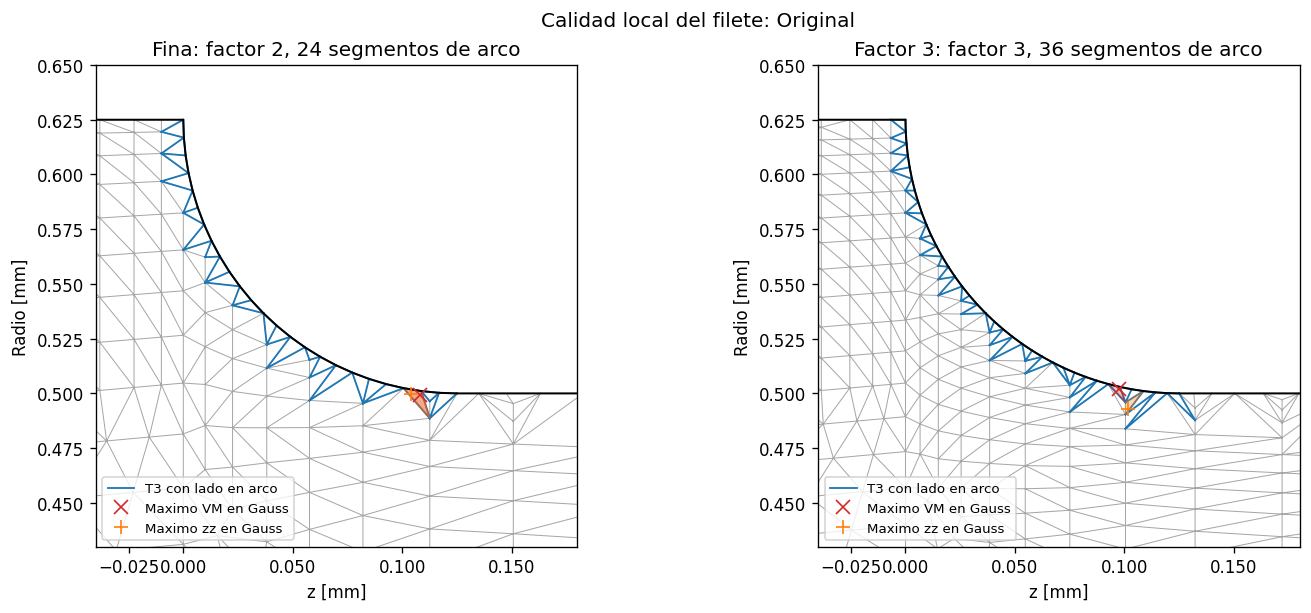

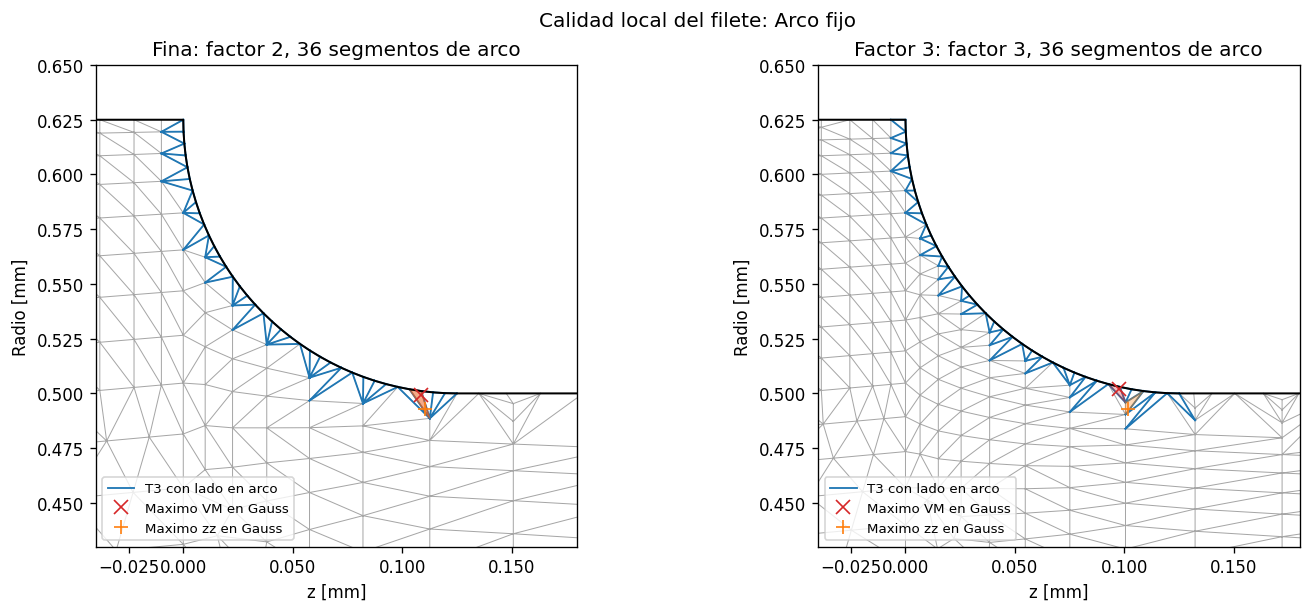

In [20]:
for estudio, resultados in estudios:
    fig, ejes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
    for ax, resultado in zip(ejes, resultados[2:]):
        factor = resultado["factor"]
        segmentos = int(n_arco*factor) if estudio == "Original" else n_arco_fijo
        coords_diag, conn_diag, bordes_diag = generar_malla_eje(
            d, D, r_transicion, L_grueso, L_delgado,
            h_cerca/factor, h_lejos/factor, int(n_radial*factor), segmentos)
        fila = next(f for f in diagnostico_filete if f["estudio"] == estudio and f["malla"] == resultado["malla"])
        ax.triplot(coords_diag[:, 1], coords_diag[:, 0], conn_diag, color="0.65", linewidth=0.6)
        ax.triplot(coords_diag[:, 1], coords_diag[:, 0], conn_diag[fila["elementos_arco"]],
                   color="tab:blue", linewidth=1.1, label="T3 con lado en arco")
        exterior_diag = coords_diag[bordes_diag["nodos_exterior"]]
        ax.plot(exterior_diag[:, 1], exterior_diag[:, 0], color="black", linewidth=1.2)
        for clave, color, marca in [("VM", "tab:red", "x"), ("zz", "tab:orange", "+")]:
            nodos = conn_diag[resultado["elemento_"+clave]]
            ax.fill(coords_diag[nodos, 1], coords_diag[nodos, 0], color=color, alpha=0.3)
            radio_max, z_max = resultado["posicion_"+clave]
            ax.plot(z_max, radio_max, marker=marca, color=color, markersize=8,
                    linestyle="none", label="Maximo "+clave+" en Gauss")
        ax.set_xlim(-0.04*d, 0.18*d)
        ax.set_ylim(0.43*d, 0.65*d)
        ax.set_aspect("equal")
        ax.set_xticks([-0.025*d, 0, 0.05*d, 0.10*d, 0.15*d])
        ax.set_xlabel("z [mm]")
        ax.set_ylabel("Radio [mm]")
        ax.set_title(f'{resultado["malla"]}: factor {factor:g}, {segmentos} segmentos de arco')
        ax.legend(loc="lower left", fontsize=8)
    fig.suptitle("Calidad local del filete: "+estudio)
    nombre = "original" if estudio == "Original" else "arco_fijo"
    fig.savefig("Graficos/diagnostico_filete_"+nombre+".png", dpi=300, bbox_inches="tight")
    plt.show()


Los elementos de los máximos en las mallas fina y factor 3 tienen ángulos mínimos entre 17.56° y 23.59°, y relaciones lado/altura entre 3.50 y 4.12. No se observa una distorsión extrema en esos elementos. En factor 3, el T3 del máximo axial de Gauss no tiene lado sobre el arco; el máximo axial del filete pertenece a otro elemento.

La distribución junto al arco sí es irregular. En el estudio original, el peor ángulo de esa fila baja de 19.23° en factor 2 a 10.20° en factor 3. En el arco fijo se mantienen valores alrededor de 10° y relaciones lado/altura hasta 6.87 en las dos mallas más finas. Esto puede influir en la sensibilidad local, pero no basta para atribuir las variaciones de tensión solamente a la calidad geométrica.

Como mejora sencilla se propone añadir una o dos filas interiores aproximadamente normales al arco, con separación comparable a la longitud de sus segmentos y una transición gradual hacia la malla interior. Se evitarían puntos existentes demasiado próximos a esas filas. La propuesta no se aplica en este diagnóstico; el generador y los resultados se conservan.
